# Projek Probabilitas dan Statistika
## Analisis Perbandingan Capaian Akademik Mahasiswa Kelas Siang dan Kelas Malam pada Mata Kuliah Manajemen Rantai Pasok
## Kelompok 8 — Kelas 3 TI B

Dataset: *Anonymized Dataset for Class Time and Academic Performance Study* (Chen, 2025; Zenodo, CC BY 4.0) — https://zenodo.org/records/15768314

Alur analisis: **Kejelasan Data → Organisasi Data → Visualisasi → Statistika Deskriptif**.
Seluruh analisis bersifat deskriptif (tanpa uji hipotesis dan tanpa model prediksi).

### BAGIAN 0 - Persiapan Colab

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Khusus Google Colab: hapus tanda # pada 2 baris di bawah, lalu upload file 3TIB_08_CapaianAkademik.xlsx
from google.colab import files
files.upload()

path = "3TIB_08_CapaianAkademik.xlsx"
dataraw = pd.read_excel(path, sheet_name="Dataset")
kamus = pd.read_excel(path, sheet_name="Kamus Variabel")

print("Tampilan 5 baris pertama dataraw:")
print(dataraw.head())

Saving 3TIB_08_CapaianAkademik.xlsx to 3TIB_08_CapaianAkademik.xlsx
Tampilan 5 baris pertama dataraw:
  StudentID  Gender  Program  YearLevel  ClassTime    Quiz  Project  \
0       F01       1        1          3          0  24.000     15.0   
1       F02       0        1          3          0  22.414     14.2   
2       F03       0        2          4          0  23.207     15.0   
3       F04       1        1          2          0  18.680     14.9   
4       F05       0        1          4          0  22.500     15.3   

     Midterm    Final  Attendance  Participation  FinalGrade  
0  21.189286  22.6800        10.0       0.764706   92.869286  
1  18.214286  19.8225        10.0       0.352941   84.650786  
2  22.142857  24.2500        10.0       0.647059   94.599857  
3  15.239286  17.6500        10.0       0.235294   76.469286  
4  17.617857  23.3950        10.0       0.058824   88.812857  


### BAGIAN 1 - Kejelasan Data

In [2]:
# Dimensi dan tipe data
print("Shape dataset awal (baris, kolom):", dataraw.shape)
print("\nTipe data tiap kolom:")
print(dataraw.dtypes)

# Unit observasi = satu mahasiswa: cek apakah ada mahasiswa yang tercatat ganda
print("\nJumlah baris duplikat (seluruh kolom):", dataraw.duplicated().sum())
print("Jumlah StudentID duplikat:", dataraw["StudentID"].duplicated().sum())

# Kamus variabel (arti, satuan, dan kode tiap kolom)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 200)
print("\nKamus variabel:")
print(kamus[["Variabel", "Deskripsi", "Satuan / kode"]].to_string(index=False))

Shape dataset awal (baris, kolom): (192, 12)

Tipe data tiap kolom:
StudentID         object
Gender             int64
Program            int64
YearLevel          int64
ClassTime          int64
Quiz             float64
Project          float64
Midterm          float64
Final            float64
Attendance       float64
Participation    float64
FinalGrade       float64
dtype: object

Jumlah baris duplikat (seluruh kolom): 0
Jumlah StudentID duplikat: 0

Kamus variabel:
     Variabel                                Deskripsi                                                                                        Satuan / kode
    StudentID         Kode anonim mahasiswa (F01-F192)                                                                                                    -
       Gender                            Jenis kelamin                                                                                 0 = Male, 1 = Female
      Program Program studi/kelompok jurusan mahasiswa 1 = bus

In [3]:
# Rentang nilai tiap variabel numerik (cek kewajaran data)
print(dataraw.drop(columns="StudentID").describe().T[["count", "min", "max"]].round(3))

# Variabel yang dianalisis
kolom_analisis = ["FinalGrade", "Final", "Attendance"]   # variabel utama (kuantitatif)
kolom_kelompok = ["ClassTime", "Gender"]                 # variabel pengelompok
print("\nVariabel utama :", kolom_analisis)
print("Variabel kelompok:", kolom_kelompok)

               count    min     max
Gender         192.0  0.000   1.000
Program        192.0  1.000   4.000
YearLevel      192.0  1.000   4.000
ClassTime      192.0  0.000   1.000
Quiz           192.0  5.233  24.000
Project        192.0  0.000  15.500
Midterm        192.0  0.000  26.071
Final          192.0  0.000  27.860
Attendance     192.0  1.500  10.000
Participation  192.0  0.000   1.286
FinalGrade     192.0  7.483  99.729

Variabel utama : ['FinalGrade', 'Final', 'Attendance']
Variabel kelompok: ['ClassTime', 'Gender']


### BAGIAN 2 - Organisasi Data

> Langkah 1: Pemeriksaan missing data

In [4]:
# Cek missing value pada seluruh kolom
missing_semua = dataraw.isnull().sum()
print("Jumlah missing value per kolom:")
print(missing_semua)
print("\nTotal missing value seluruh dataset:", missing_semua.sum())

Jumlah missing value per kolom:
StudentID        0
Gender           0
Program          0
YearLevel        0
ClassTime        0
Quiz             0
Project          0
Midterm          0
Final            0
Attendance       0
Participation    0
FinalGrade       0
dtype: int64

Total missing value seluruh dataset: 0


> Langkah 2: Pemeriksaan nilai nol dan nilai di luar kebiasaan

In [5]:
# Nilai 0 pada komponen penilaian (kemungkinan tidak mengumpulkan / tidak mengikuti)
for kolom in ["Project", "Midterm", "Final", "Participation"]:
    print(f"Jumlah nilai 0 pada {kolom:13s}:", (dataraw[kolom] == 0).sum())

# Partisipasi yang nilainya di atas 1 (skala tidak dijelaskan pengunggah)
print("\nJumlah Participation > 1:", (dataraw["Participation"] > 1).sum())

# Keputusan: seluruh 192 mahasiswa tetap dianalisis karena tidak ada alasan jelas
# untuk membuang data asli; nilai 0 dan nilai rendah dilaporkan apa adanya.
print("\nMahasiswa dengan skor ujian akhir 0:")
print(dataraw.loc[dataraw["Final"] == 0, ["StudentID", "ClassTime", "Final", "FinalGrade"]])

Jumlah nilai 0 pada Project      : 5
Jumlah nilai 0 pada Midterm      : 1
Jumlah nilai 0 pada Final        : 2
Jumlah nilai 0 pada Participation: 36

Jumlah Participation > 1: 2

Mahasiswa dengan skor ujian akhir 0:
   StudentID  ClassTime  Final  FinalGrade
65       F66          0    0.0   40.445571
75       F76          0    0.0   13.773429


> Langkah 3: Pengelompokan dan pelabelan data

In [6]:
data = dataraw.copy()

# Label sesuai kamus variabel (kode 0/1 diberi nama kelompok)
data["kelas"] = data["ClassTime"].map({0: "Kelas Siang", 1: "Kelas Malam"})
data["jenis_kelamin"] = data["Gender"].map({0: "Laki-laki", 1: "Perempuan"})
data["angkatan"] = data["YearLevel"].map({1: "Freshman", 2: "Sophomore", 3: "Junior", 4: "Senior"})

# Definisikan variabel utama untuk analisis selanjutnya
nilai_akhir = data["FinalGrade"]
nilai_uas = data["Final"]
kehadiran = data["Attendance"]

print("Jumlah mahasiswa yang dianalisis (Count):", len(data))
print(data[["StudentID", "kelas", "jenis_kelamin", "angkatan"]].head())

Jumlah mahasiswa yang dianalisis (Count): 192
  StudentID        kelas jenis_kelamin   angkatan
0       F01  Kelas Siang     Perempuan     Junior
1       F02  Kelas Siang     Laki-laki     Junior
2       F03  Kelas Siang     Laki-laki     Senior
3       F04  Kelas Siang     Perempuan  Sophomore
4       F05  Kelas Siang     Laki-laki     Senior


### BAGIAN 3 - Distribusi Frekuensi dan Probabilitas Empiris

In [7]:
# Tabel frekuensi dan persentase kelas
frq_kelas = pd.crosstab(index=data["kelas"], columns="Frekuensi")
pct_kelas = pd.crosstab(index=data["kelas"], columns="Persentase (%)", normalize=True) * 100
print("Tabel Frekuensi Kelas:")
print(frq_kelas)
print("\nTabel Persentase Kelas:")
print(round(pct_kelas, 2))

# Tabel frekuensi jenis kelamin dan angkatan
print("\nTabel Frekuensi Jenis Kelamin:")
print(pd.crosstab(index=data["jenis_kelamin"], columns="Frekuensi"))
print("\nTabel Frekuensi Angkatan:")
print(pd.crosstab(index=data["angkatan"], columns="Frekuensi"))

# Tabel kontingensi kelas x jenis kelamin
print("\nTabel Kontingensi Kelas x Jenis Kelamin:")
print(pd.crosstab(data["kelas"], data["jenis_kelamin"], margins=True))

Tabel Frekuensi Kelas:
col_0        Frekuensi
kelas                 
Kelas Malam         50
Kelas Siang        142

Tabel Persentase Kelas:
col_0        Persentase (%)
kelas                      
Kelas Malam           26.04
Kelas Siang           73.96

Tabel Frekuensi Jenis Kelamin:
col_0          Frekuensi
jenis_kelamin           
Laki-laki            100
Perempuan             92

Tabel Frekuensi Angkatan:
col_0      Frekuensi
angkatan            
Freshman           2
Junior           100
Senior            81
Sophomore          9

Tabel Kontingensi Kelas x Jenis Kelamin:
jenis_kelamin  Laki-laki  Perempuan  All
kelas                                   
Kelas Malam           23         27   50
Kelas Siang           77         65  142
All                  100         92  192


In [8]:
# Distribusi frekuensi nilai akhir (kelas interval lebar 10)
batas = list(range(0, 101, 10))
interval = pd.cut(nilai_akhir, bins=batas, right=False)
frq_nilai = interval.value_counts().sort_index()
tabel_frekuensi = pd.DataFrame({
    "Frekuensi": frq_nilai,
    "Persentase (%)": (frq_nilai / len(nilai_akhir) * 100).round(2),
    "Frekuensi kumulatif": frq_nilai.cumsum(),
})
print("Distribusi Frekuensi Nilai Akhir:")
print(tabel_frekuensi)

# Distribusi frekuensi nilai akhir per kelas
print("\nDistribusi Frekuensi Nilai Akhir menurut Kelas:")
print(pd.crosstab(interval, data["kelas"]))

Distribusi Frekuensi Nilai Akhir:
            Frekuensi  Persentase (%)  Frekuensi kumulatif
FinalGrade                                                
[0, 10)             1            0.52                    1
[10, 20)            1            0.52                    2
[20, 30)            1            0.52                    3
[30, 40)            2            1.04                    5
[40, 50)            2            1.04                    7
[50, 60)            2            1.04                    9
[60, 70)           11            5.73                   20
[70, 80)           55           28.65                   75
[80, 90)           83           43.23                  158
[90, 100)          34           17.71                  192

Distribusi Frekuensi Nilai Akhir menurut Kelas:
kelas       Kelas Malam  Kelas Siang
FinalGrade                          
[0, 10)               0            1
[10, 20)              0            1
[20, 30)              0            1
[30, 40)              0 

In [9]:
# Probabilitas empiris P(A) = n(A) / N
N = len(data)
malam = data["kelas"] == "Kelas Malam"
siang = data["kelas"] == "Kelas Siang"
print("Probabilitas empiris (N =", N, "):")
print("P(Kelas Malam)                       =", round(malam.sum() / N, 4))
print("P(nilai akhir >= 80)                 =", round((nilai_akhir >= 80).sum() / N, 4))
print("P(kehadiran penuh, skor 10)          =", round((kehadiran == 10).sum() / N, 4))
print("P(nilai akhir > mean)                =", round((nilai_akhir > nilai_akhir.mean()).sum() / N, 4))

# Probabilitas bersyarat P(A|B) = n(A dan B) / n(B)
print("\nProbabilitas bersyarat:")
print("P(nilai akhir >= 80 | Kelas Siang)   =", round(((nilai_akhir >= 80) & siang).sum() / siang.sum(), 4))
print("P(nilai akhir >= 80 | Kelas Malam)   =", round(((nilai_akhir >= 80) & malam).sum() / malam.sum(), 4))
print("P(kehadiran penuh | Kelas Siang)     =", round(((kehadiran == 10) & siang).sum() / siang.sum(), 4))
print("P(kehadiran penuh | Kelas Malam)     =", round(((kehadiran == 10) & malam).sum() / malam.sum(), 4))

Probabilitas empiris (N = 192 ):
P(Kelas Malam)                       = 0.2604
P(nilai akhir >= 80)                 = 0.6094
P(kehadiran penuh, skor 10)          = 0.6615
P(nilai akhir > mean)                = 0.599

Probabilitas bersyarat:
P(nilai akhir >= 80 | Kelas Siang)   = 0.5845
P(nilai akhir >= 80 | Kelas Malam)   = 0.68
P(kehadiran penuh | Kelas Siang)     = 0.6408
P(kehadiran penuh | Kelas Malam)     = 0.72


### BAGIAN 4 - Visualisasi Data (Grafik)

> Histogram dan Boxplot Nilai Akhir

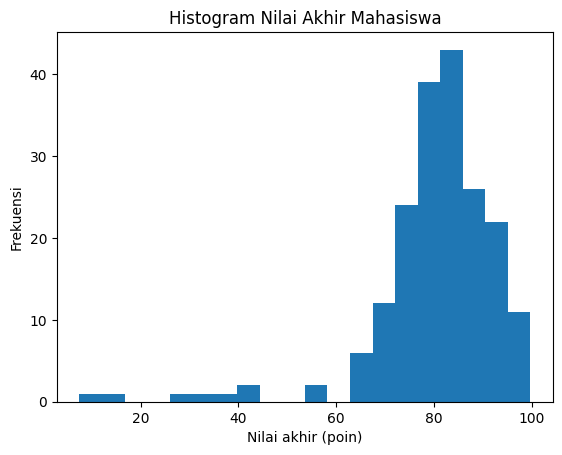

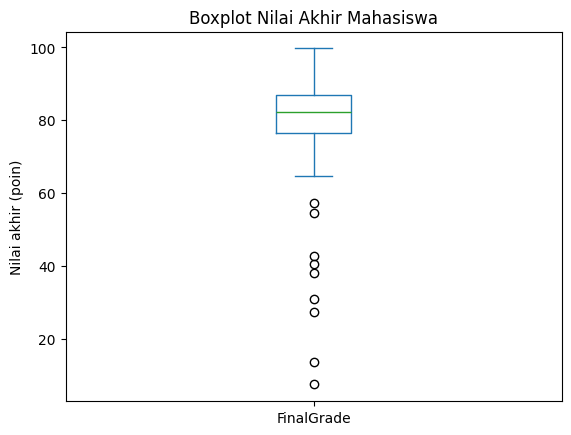

In [10]:
nilai_akhir.plot(kind="hist", bins=20, title="Histogram Nilai Akhir Mahasiswa")
plt.xlabel("Nilai akhir (poin)"); plt.ylabel("Frekuensi"); plt.show()

nilai_akhir.plot(kind="box", title="Boxplot Nilai Akhir Mahasiswa")
plt.ylabel("Nilai akhir (poin)"); plt.show()

> Histogram dan Boxplot Skor Ujian Akhir

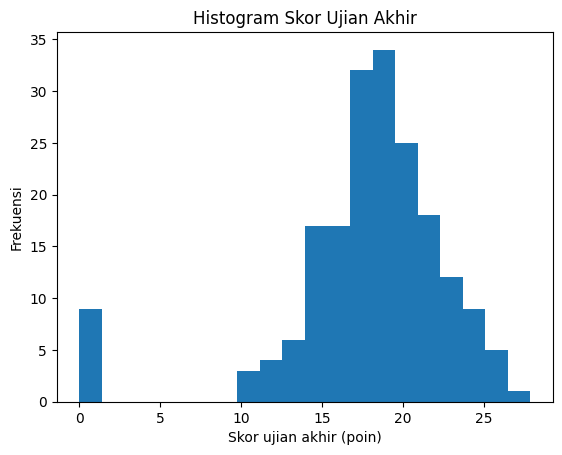

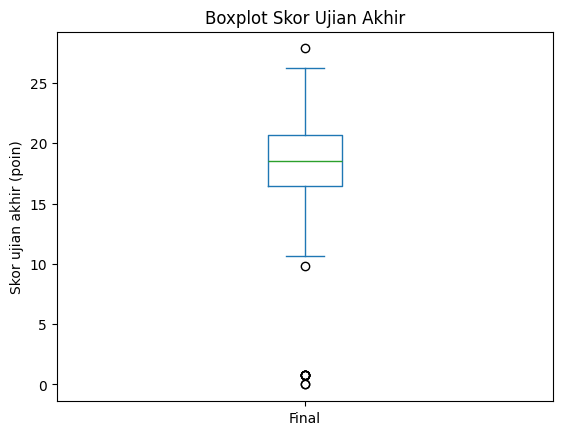

In [11]:
nilai_uas.plot(kind="hist", bins=20, title="Histogram Skor Ujian Akhir")
plt.xlabel("Skor ujian akhir (poin)"); plt.ylabel("Frekuensi"); plt.show()

nilai_uas.plot(kind="box", title="Boxplot Skor Ujian Akhir")
plt.ylabel("Skor ujian akhir (poin)"); plt.show()

> Histogram dan Boxplot Kehadiran

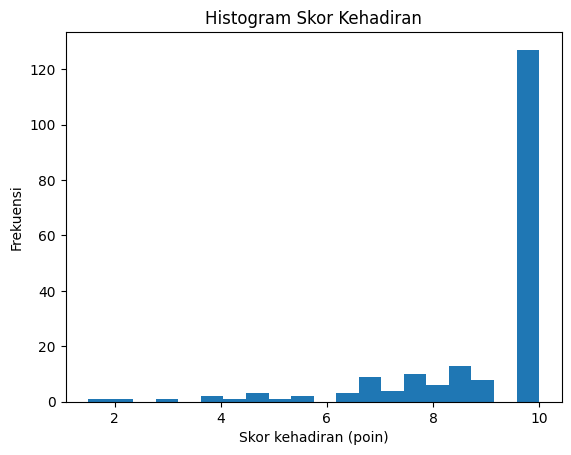

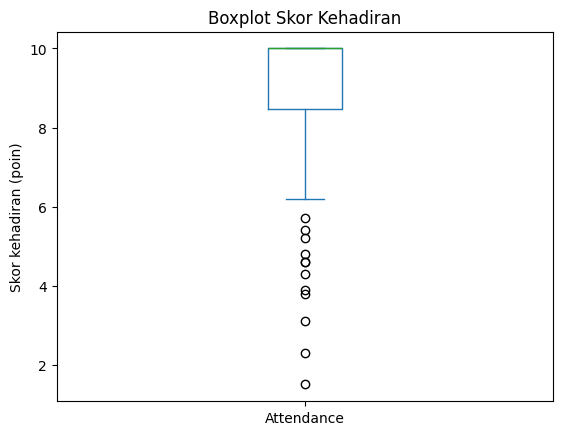

In [12]:
kehadiran.plot(kind="hist", bins=20, title="Histogram Skor Kehadiran")
plt.xlabel("Skor kehadiran (poin)"); plt.ylabel("Frekuensi"); plt.show()

kehadiran.plot(kind="box", title="Boxplot Skor Kehadiran")
plt.ylabel("Skor kehadiran (poin)"); plt.show()

> Perbandingan Kelas Siang dan Kelas Malam

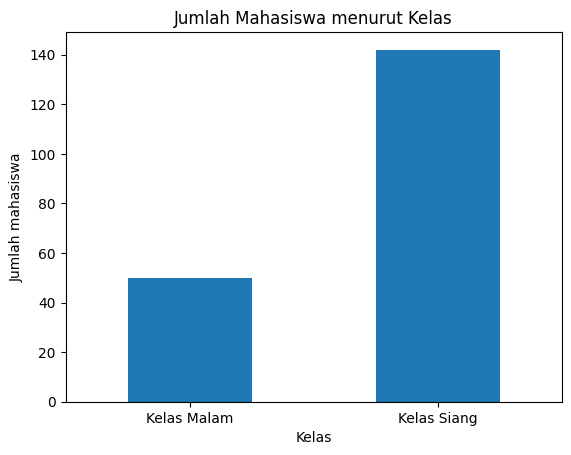

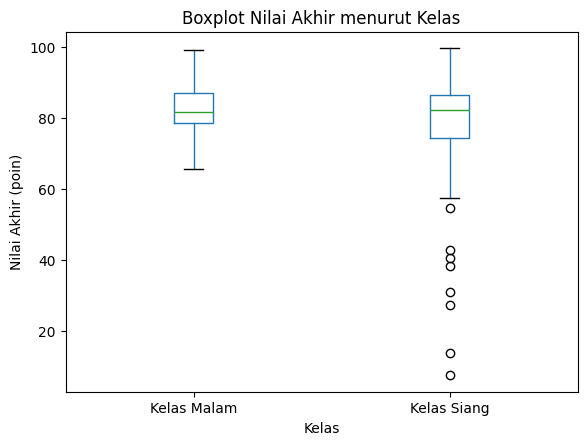

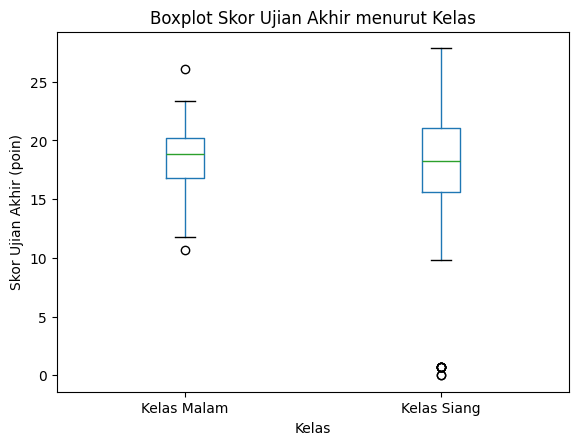

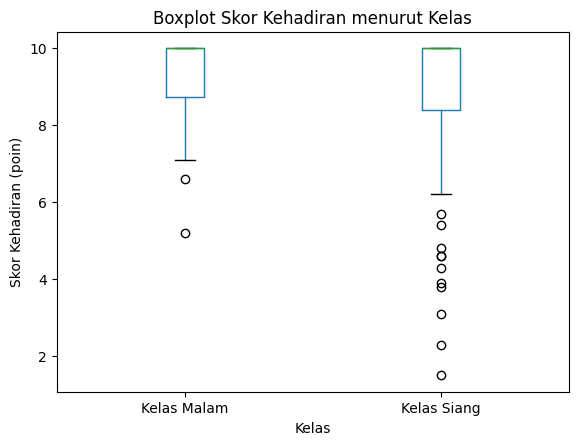

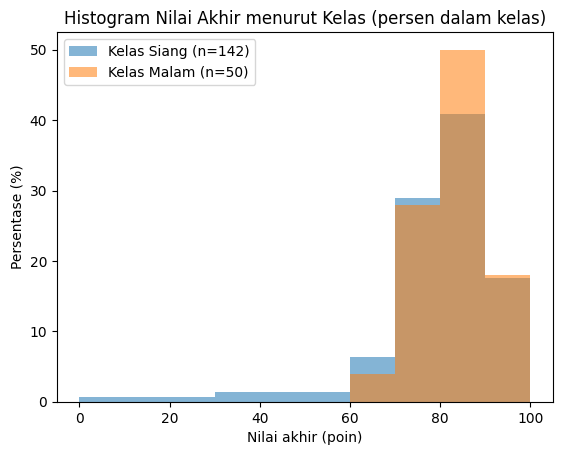

In [13]:
frq_kelas["Frekuensi"].plot(kind="bar", rot=0, title="Jumlah Mahasiswa menurut Kelas")
plt.xlabel("Kelas"); plt.ylabel("Jumlah mahasiswa"); plt.show()

for kolom, nama in [("FinalGrade", "Nilai Akhir"), ("Final", "Skor Ujian Akhir"), ("Attendance", "Skor Kehadiran")]:
    data.boxplot(column=kolom, by="kelas", grid=False)
    plt.suptitle(""); plt.title(f"Boxplot {nama} menurut Kelas")
    plt.xlabel("Kelas"); plt.ylabel(f"{nama} (poin)"); plt.show()

# Histogram nilai akhir per kelas (dalam persen agar kedua kelas sebanding)
for nama_kelas, warna in [("Kelas Siang", "tab:blue"), ("Kelas Malam", "tab:orange")]:
    s = data.loc[data["kelas"] == nama_kelas, "FinalGrade"]
    plt.hist(s, bins=np.arange(0, 101, 10), weights=np.ones(len(s)) / len(s) * 100,
             alpha=0.55, label=f"{nama_kelas} (n={len(s)})", color=warna)
plt.title("Histogram Nilai Akhir menurut Kelas (persen dalam kelas)")
plt.xlabel("Nilai akhir (poin)"); plt.ylabel("Persentase (%)"); plt.legend(); plt.show()

### BAGIAN 5 - Statistika Deskriptif (16 Metrik)

In [ ]:
def modus(s, desimal=0):
    """Modus dihitung dari nilai yang dibulatkan, karena nilai kontinu jarang berulang persis."""
    return s.round(desimal).mode().iloc[0]

def ringkasan(s):
    """16 metrik statistika deskriptif untuk satu variabel numerik."""
    return pd.Series({
        "Count (n)": s.count(),
        "Total": s.sum(),
        "Mean": s.mean(),
        "Median": s.median(),
        "Modus": modus(s),
        "Q1": s.quantile(0.25),
        "Q2 (Median)": s.quantile(0.50),
        "Q3": s.quantile(0.75),
        "Min": s.min(),
        "Max": s.max(),
        "Range": s.max() - s.min(),
        "Varians": s.var(),
        "Standar Deviasi": s.std(),
        "Koefisien Variasi (%)": s.std() / s.mean() * 100,
        "Skewness": s.skew(),
        "Standard Error": s.sem(),
    })

tabel_deskriptif = pd.DataFrame({
    "Nilai Akhir": ringkasan(nilai_akhir),
    "Skor Ujian Akhir": ringkasan(nilai_uas),
    "Skor Kehadiran": ringkasan(kehadiran),
})
print("Statistika Deskriptif (16 metrik), seluruh mahasiswa:")
print(round(tabel_deskriptif, 4))
print("\nCatatan: Modus dihitung dari nilai yang dibulatkan ke bilangan bulat.")

In [ ]:
# Pelengkap: IQR (Q3 - Q1) dan batas pencilan boxplot (bukan bagian dari 16 metrik)
for nama, s in [("Nilai Akhir", nilai_akhir), ("Skor Ujian Akhir", nilai_uas), ("Skor Kehadiran", kehadiran)]:
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    bawah, atas = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_pencilan = ((s < bawah) | (s > atas)).sum()
    print(f"{nama:18s} IQR = {iqr:.2f} | Batas bawah = {bawah:.2f} | Batas atas = {atas:.2f} | Pencilan = {n_pencilan}")

### BAGIAN 6 - Perbandingan Deskriptif Kelas Siang dan Kelas Malam

In [ ]:
# 16 metrik Nilai Akhir untuk tiap kelas
tabel_kelas = pd.DataFrame({
    nama: ringkasan(grup["FinalGrade"]) for nama, grup in data.groupby("kelas")
})
print("Statistika Deskriptif Nilai Akhir menurut Kelas (16 metrik):")
print(round(tabel_kelas, 4))

In [ ]:
# 16 metrik Skor Ujian Akhir dan Skor Kehadiran untuk tiap kelas
for kolom, nama in [("Final", "Skor Ujian Akhir"), ("Attendance", "Skor Kehadiran")]:
    tabel = pd.DataFrame({k: ringkasan(g[kolom]) for k, g in data.groupby("kelas")})
    print(f"\nStatistika Deskriptif {nama} menurut Kelas (16 metrik):")
    print(round(tabel, 4))

In [ ]:
# Ringkasan selisih Kelas Malam terhadap Kelas Siang (deskriptif, bukan uji hipotesis)
selisih = pd.DataFrame({
    "Selisih Mean (Malam - Siang)": tabel_kelas.loc["Mean", "Kelas Malam"] - tabel_kelas.loc["Mean", "Kelas Siang"],
    "Selisih Median (Malam - Siang)": tabel_kelas.loc["Median", "Kelas Malam"] - tabel_kelas.loc["Median", "Kelas Siang"],
    "Rasio SD (Malam / Siang)": tabel_kelas.loc["Standar Deviasi", "Kelas Malam"] / tabel_kelas.loc["Standar Deviasi", "Kelas Siang"],
    "Selisih CV (poin persen)": tabel_kelas.loc["Koefisien Variasi (%)", "Kelas Malam"] - tabel_kelas.loc["Koefisien Variasi (%)", "Kelas Siang"],
}, index=["Nilai Akhir"]).T
print("Perbandingan Nilai Akhir antar Kelas:")
print(round(selisih, 4))

### BAGIAN 7 - Gambaran Deskriptif menurut Jenis Kelamin

In [ ]:
deskriptif_gender = data.groupby("jenis_kelamin")["FinalGrade"].agg(
    ["count", "mean", "median", "std", "min", "max"])
deskriptif_gender["Q1"] = data.groupby("jenis_kelamin")["FinalGrade"].quantile(0.25)
deskriptif_gender["Q3"] = data.groupby("jenis_kelamin")["FinalGrade"].quantile(0.75)
print("Deskriptif Nilai Akhir menurut Jenis Kelamin:")
print(round(deskriptif_gender, 2))

# Rata-rata nilai akhir menurut kelas dan jenis kelamin
print("\nRata-rata Nilai Akhir menurut Kelas x Jenis Kelamin:")
print(round(data.pivot_table(values="FinalGrade", index="kelas", columns="jenis_kelamin", aggfunc="mean"), 2))
print("\nJumlah mahasiswa menurut Kelas x Jenis Kelamin:")
print(data.pivot_table(values="FinalGrade", index="kelas", columns="jenis_kelamin", aggfunc="count"))

data.boxplot(column="FinalGrade", by="jenis_kelamin", grid=False)
plt.suptitle(""); plt.title("Boxplot Nilai Akhir menurut Jenis Kelamin")
plt.xlabel("Jenis kelamin"); plt.ylabel("Nilai akhir (poin)"); plt.show()